In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
bars = pd.read_csv('mock3_data/bars.csv', parse_dates=['ts'])
book = pd.read_csv('mock3_data/book.csv', parse_dates=['minute'])
vendor_signal = pd.read_csv('mock3_data/vendor_signal.csv', parse_dates=['published_at'])

In [3]:
bars

,ts,instrument,mid_close,spread_close,last_price,buy_volume,sell_volume,n_trades
0,2024-01-02 09:31:00,HRN,1998.300,0.20,1998.20,80,474,268
1,2024-01-02 09:31:00,KST,4997.625,0.25,4997.75,1269,978,585
2,2024-01-02 09:31:00,PLV,798.850,0.10,798.80,28,570,316
3,2024-01-02 09:32:00,HRN,1999.000,0.20,1998.90,191,319,241
4,2024-01-02 09:32:00,KST,4997.625,0.25,4997.75,265,1161,334
...,...,...,...,...,...,...,...,...
145743,2024-06-28 15:59:00,KST,4042.125,0.25,4042.25,5570,12,1476
145744,2024-06-28 15:59:00,PLV,691.625,0.15,691.70,871,4,410
145745,2024-06-28 16:00:00,HRN,1529.600,0.20,1529.70,329,168,256
145746,2024-06-28 16:00:00,KST,4042.125,0.25,4042.00,241,698,251


In [4]:
book

,minute,instrument,bid_px1,ask_px1,bid_sz1,ask_sz1,bid_sz2,ask_sz2
0,2024-01-02 09:30:00,HRN,1998.20,1998.40,40,36,136,45
1,2024-01-02 09:30:00,KST,4997.50,4997.75,72,7,41,55
2,2024-01-02 09:30:00,PLV,798.80,798.90,38,1,30,26
3,2024-01-02 09:31:00,HRN,1998.90,1999.10,13,57,8,83
4,2024-01-02 09:31:00,KST,4997.50,4997.75,157,29,51,162
...,...,...,...,...,...,...,...,...
145293,2024-06-28 15:58:00,KST,4042.00,4042.25,93,5,135,3
145294,2024-06-28 15:58:00,PLV,691.55,691.70,25,9,37,1
145295,2024-06-28 15:59:00,HRN,1529.50,1529.70,33,44,21,127
145296,2024-06-28 15:59:00,KST,4042.00,4042.25,165,3,232,4


In [5]:
vendor_signal

,published_at,instrument,signal
0,2024-01-02 09:35:00,HRN,-0.1991
1,2024-01-02 09:35:00,KST,-1.8237
2,2024-01-02 09:35:00,PLV,0.2963
3,2024-01-02 09:40:00,HRN,-0.6262
4,2024-01-02 09:40:00,KST,1.2475
...,...,...,...
29133,2024-06-28 15:55:00,KST,0.5844
29134,2024-06-28 15:55:00,PLV,-1.1904
29135,2024-06-28 16:00:00,HRN,1.8414
29136,2024-06-28 16:00:00,KST,-0.6762


In [6]:
bars.describe()

,ts,mid_close,spread_close,last_price,buy_volume,sell_volume,n_trades
count,145748,145748.000000,145748.000000,145748.000000,145748.000000,145748.000000,145748.000000
mean,2024-04-01 06:21:19.648983296,2407.636384,0.192530,2407.635841,369.223036,372.798158,256.996370
min,2024-01-02 09:31:00,602.250000,0.100000,602.300000,0.000000,0.000000,17.000000
25%,2024-02-15 10:26:00,809.050000,0.100000,809.050000,84.000000,84.000000,135.000000
50%,2024-04-02 14:29:00,1952.800000,0.200000,1952.850000,198.000000,199.000000,205.000000
75%,2024-05-15 15:05:00,4111.375000,0.250000,4111.250000,440.000000,446.000000,315.000000
max,2024-06-28 16:00:00,5271.750000,1.250000,5271.500000,23389.000000,22114.000000,5856.000000
std,NaN,1661.173567,0.079916,1661.173163,531.271916,534.385406,194.562384


In [7]:
book.describe()

,minute,bid_px1,ask_px1,bid_sz1,ask_sz1,bid_sz2,ask_sz2
count,145298,145298.000000,145298.000000,145298.000000,145298.000000,145298.000000,145298.000000
mean,2024-04-01 03:30:36.778895872,2408.988028,2409.180441,38.812626,38.831388,65.051260,65.051019
min,2024-01-02 09:30:00,602.200000,602.300000,1.000000,1.000000,1.000000,1.000000
25%,2024-02-15 09:48:00,808.850000,808.950000,12.000000,12.000000,18.000000,18.000000
50%,2024-04-02 13:13:00,1953.900000,1954.100000,28.000000,28.000000,44.000000,44.000000
75%,2024-05-15 15:41:00,4112.000000,4112.250000,53.000000,53.000000,87.000000,87.000000
max,2024-06-28 15:59:00,5271.500000,5272.000000,614.000000,572.000000,1465.000000,932.000000
std,NaN,1662.848676,1662.908516,38.179117,38.064480,70.176117,69.651938


In [8]:
bars[bars.duplicated(subset=['ts', 'instrument'])]

,ts,instrument,mid_close,spread_close,last_price,buy_volume,sell_volume,n_trades
107170,2024-05-14 10:01:00,KST,4090.875,0.25,4091.00,300,69,80
107174,2024-05-14 10:02:00,KST,4087.375,0.25,4087.25,25,2414,576
107178,2024-05-14 10:03:00,KST,4086.625,0.25,4086.50,303,1122,364
107182,2024-05-14 10:04:00,KST,4086.125,0.25,4086.00,140,895,241
107186,2024-05-14 10:05:00,KST,4082.375,0.25,4082.25,12,1951,487
107190,2024-05-14 10:06:00,KST,4082.125,0.25,4082.00,60,456,117
107194,2024-05-14 10:07:00,KST,4080.625,0.25,4080.50,177,1584,485
107198,2024-05-14 10:08:00,KST,4079.125,0.25,4079.00,405,1811,547
107202,2024-05-14 10:09:00,KST,4078.625,0.25,4078.50,302,358,174
107206,2024-05-14 10:10:00,KST,4077.625,0.25,4077.50,278,2237,643


In [9]:
bars = bars.drop_duplicates(subset=['ts', 'instrument'])
bars

,ts,instrument,mid_close,spread_close,last_price,buy_volume,sell_volume,n_trades
0,2024-01-02 09:31:00,HRN,1998.300,0.20,1998.20,80,474,268
1,2024-01-02 09:31:00,KST,4997.625,0.25,4997.75,1269,978,585
2,2024-01-02 09:31:00,PLV,798.850,0.10,798.80,28,570,316
3,2024-01-02 09:32:00,HRN,1999.000,0.20,1998.90,191,319,241
4,2024-01-02 09:32:00,KST,4997.625,0.25,4997.75,265,1161,334
...,...,...,...,...,...,...,...,...
145743,2024-06-28 15:59:00,KST,4042.125,0.25,4042.25,5570,12,1476
145744,2024-06-28 15:59:00,PLV,691.625,0.15,691.70,871,4,410
145745,2024-06-28 16:00:00,HRN,1529.600,0.20,1529.70,329,168,256
145746,2024-06-28 16:00:00,KST,4042.125,0.25,4042.00,241,698,251


In [ ]:
book['ts'] = book['minute'] + pd.Timedelta(minutes=1)
df = pd.merge(bars, book, on=['ts', 'instrument'], how='left')
df

,ts,instrument,mid_close,spread_close,last_price,buy_volume,sell_volume,n_trades,minute,bid_px1,ask_px1,bid_sz1,ask_sz1,bid_sz2,ask_sz2
0,2024-01-02 09:31:00,HRN,1998.300,0.20,1998.20,80,474,268,2024-01-02 09:30:00,1998.20,1998.40,40.0,36.0,136.0,45.0
1,2024-01-02 09:31:00,KST,4997.625,0.25,4997.75,1269,978,585,2024-01-02 09:30:00,4997.50,4997.75,72.0,7.0,41.0,55.0
2,2024-01-02 09:31:00,PLV,798.850,0.10,798.80,28,570,316,2024-01-02 09:30:00,798.80,798.90,38.0,1.0,30.0,26.0
3,2024-01-02 09:32:00,HRN,1999.000,0.20,1998.90,191,319,241,2024-01-02 09:31:00,1998.90,1999.10,13.0,57.0,8.0,83.0
4,2024-01-02 09:32:00,KST,4997.625,0.25,4997.75,265,1161,334,2024-01-02 09:31:00,4997.50,4997.75,157.0,29.0,51.0,162.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
145683,2024-06-28 15:59:00,KST,4042.125,0.25,4042.25,5570,12,1476,2024-06-28 15:58:00,4042.00,4042.25,93.0,5.0,135.0,3.0
145684,2024-06-28 15:59:00,PLV,691.625,0.15,691.70,871,4,410,2024-06-28 15:58:00,691.55,691.70,25.0,9.0,37.0,1.0
145685,2024-06-28 16:00:00,HRN,1529.600,0.20,1529.70,329,168,256,2024-06-28 15:59:00,1529.50,1529.70,33.0,44.0,21.0,127.0
145686,2024-06-28 16:00:00,KST,4042.125,0.25,4042.00,241,698,251,2024-06-28 15:59:00,4042.00,4042.25,165.0,3.0,232.0,4.0


In [16]:
df[df['minute'].isnull()]

,ts,instrument,mid_close,spread_close,last_price,buy_volume,sell_volume,n_trades,minute,bid_px1,ask_px1,bid_sz1,ask_sz1,bid_sz2,ask_sz2
102398,2024-05-08 09:31:00,HRN,1601.30,0.2,1601.4,171,258,209,NaT,NaN,NaN,NaN,NaN,NaN,NaN
102401,2024-05-08 09:32:00,HRN,1601.20,0.2,1601.1,192,699,430,NaT,NaN,NaN,NaN,NaN,NaN,NaN
102404,2024-05-08 09:33:00,HRN,1601.60,0.2,1601.5,187,230,191,NaT,NaN,NaN,NaN,NaN,NaN,NaN
102407,2024-05-08 09:34:00,HRN,1600.35,0.3,1600.2,119,785,466,NaT,NaN,NaN,NaN,NaN,NaN,NaN
102410,2024-05-08 09:35:00,HRN,1601.10,0.2,1601.2,357,125,242,NaT,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103553,2024-05-08 15:56:00,HRN,1607.00,0.2,1607.1,735,28,393,NaT,NaN,NaN,NaN,NaN,NaN,NaN
103556,2024-05-08 15:57:00,HRN,1607.50,0.2,1607.6,517,41,275,NaT,NaN,NaN,NaN,NaN,NaN,NaN
103559,2024-05-08 15:58:00,HRN,1605.40,0.2,1605.3,7,800,417,NaT,NaN,NaN,NaN,NaN,NaN,NaN
103562,2024-05-08 15:59:00,HRN,1604.80,0.2,1604.7,81,420,259,NaT,NaN,NaN,NaN,NaN,NaN,NaN


In [19]:
df['date'] = df['ts'].dt.normalize()
df['ret'] = df.groupby(['date', 'instrument'])['mid_close'].pct_change()
df

,ts,instrument,mid_close,spread_close,last_price,buy_volume,sell_volume,n_trades,minute,bid_px1,ask_px1,bid_sz1,ask_sz1,bid_sz2,ask_sz2,ret,date
0,2024-01-02 09:31:00,HRN,1998.300,0.20,1998.20,80,474,268,2024-01-02 09:30:00,1998.20,1998.40,40.0,36.0,136.0,45.0,NaN,2024-01-02
1,2024-01-02 09:31:00,KST,4997.625,0.25,4997.75,1269,978,585,2024-01-02 09:30:00,4997.50,4997.75,72.0,7.0,41.0,55.0,NaN,2024-01-02
2,2024-01-02 09:31:00,PLV,798.850,0.10,798.80,28,570,316,2024-01-02 09:30:00,798.80,798.90,38.0,1.0,30.0,26.0,NaN,2024-01-02
3,2024-01-02 09:32:00,HRN,1999.000,0.20,1998.90,191,319,241,2024-01-02 09:31:00,1998.90,1999.10,13.0,57.0,8.0,83.0,0.000350,2024-01-02
4,2024-01-02 09:32:00,KST,4997.625,0.25,4997.75,265,1161,334,2024-01-02 09:31:00,4997.50,4997.75,157.0,29.0,51.0,162.0,0.000000,2024-01-02
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
145683,2024-06-28 15:59:00,KST,4042.125,0.25,4042.25,5570,12,1476,2024-06-28 15:58:00,4042.00,4042.25,93.0,5.0,135.0,3.0,0.002045,2024-06-28
145684,2024-06-28 15:59:00,PLV,691.625,0.15,691.70,871,4,410,2024-06-28 15:58:00,691.55,691.70,25.0,9.0,37.0,1.0,0.002282,2024-06-28
145685,2024-06-28 16:00:00,HRN,1529.600,0.20,1529.70,329,168,256,2024-06-28 15:59:00,1529.50,1529.70,33.0,44.0,21.0,127.0,-0.000196,2024-06-28
145686,2024-06-28 16:00:00,KST,4042.125,0.25,4042.00,241,698,251,2024-06-28 15:59:00,4042.00,4042.25,165.0,3.0,232.0,4.0,0.000000,2024-06-28


In [64]:
hrn_ret = df.loc[df['instrument'] == 'HRN', ['ts', 'date', 'ret']]
kst_ret = df.loc[df['instrument'] == 'KST', ['ts', 'date', 'ret']]
plv_ret = df.loc[df['instrument'] == 'PLV', ['ts', 'date', 'ret']]
print("HRN description:", hrn_ret.describe())
print("KST description:", kst_ret.describe())
print("PLV description:", plv_ret.describe())

HRN description:                                   ts                           date  \
count                          48570                          48570   
mean   2024-04-01 05:47:04.502779392  2024-03-31 17:01:57.850525184   
min              2024-01-02 09:31:00            2024-01-02 00:00:00   
25%              2024-02-15 10:23:15            2024-02-15 00:00:00   
50%              2024-04-02 14:15:30            2024-04-02 00:00:00   
75%              2024-05-15 15:07:45            2024-05-15 00:00:00   
max              2024-06-28 16:00:00            2024-06-28 00:00:00   
std                              NaN                            NaN   

                ret  
count  48445.000000  
mean      -0.000007  
min       -0.016435  
25%       -0.000308  
50%        0.000000  
75%        0.000302  
max        0.008761  
std        0.000685  
KST description:                                   ts                           date  \
count                          48570                     

In [65]:
def time_check(df):
    df['date'] = df['ts'].dt.normalize()
    df['time_delta'] = df.groupby('date')['ts'].diff()
    return (df['time_delta'].dropna() != pd.Timedelta(minutes=1)).sum()

In [66]:
print("HRN time check:", time_check(hrn_ret))
print("KST time check:", time_check(kst_ret))
print("PLV time check:", time_check(plv_ret))

HRN time check: 0
KST time check: 0
PLV time check: 1


In [67]:
set(hrn_ret['ts'].values) - set(plv_ret['ts'].values)

{numpy.datetime64('2024-02-21T11:03:00.000000000'),
 numpy.datetime64('2024-02-21T11:04:00.000000000'),
 numpy.datetime64('2024-02-21T11:05:00.000000000'),
 numpy.datetime64('2024-02-21T11:06:00.000000000'),
 numpy.datetime64('2024-02-21T11:07:00.000000000'),
 numpy.datetime64('2024-02-21T11:08:00.000000000'),
 numpy.datetime64('2024-02-21T11:09:00.000000000'),
 numpy.datetime64('2024-02-21T11:10:00.000000000'),
 numpy.datetime64('2024-02-21T11:11:00.000000000'),
 numpy.datetime64('2024-02-21T11:12:00.000000000'),
 numpy.datetime64('2024-02-21T11:13:00.000000000'),
 numpy.datetime64('2024-02-21T11:14:00.000000000'),
 numpy.datetime64('2024-02-21T11:15:00.000000000'),
 numpy.datetime64('2024-02-21T11:16:00.000000000'),
 numpy.datetime64('2024-02-21T11:17:00.000000000'),
 numpy.datetime64('2024-02-21T11:18:00.000000000'),
 numpy.datetime64('2024-02-21T11:19:00.000000000'),
 numpy.datetime64('2024-02-21T11:20:00.000000000'),
 numpy.datetime64('2024-02-21T11:21:00.000000000'),
 numpy.datet

In [68]:
def recover_time(hrn_ret, plv_ret):
    whole = pd.merge(hrn_ret[['ts', 'ret']], plv_ret.rename(columns={'ret': 'plv_ret'}), on='ts', how='left')
    return whole[['ts', 'date', 'plv_ret']].rename(columns={'plv_ret': 'ret'})
plv_ret = recover_time(hrn_ret, plv_ret)

In [69]:
plv_ret.describe()

,ts,date,ret
count,48570,48548,48423.000000
mean,2024-04-01 05:47:04.502779392,2024-03-31 17:27:52.604432896,-0.000004
min,2024-01-02 09:31:00,2024-01-02 00:00:00,-0.019115
25%,2024-02-15 10:23:15,2024-02-15 00:00:00,-0.000367
50%,2024-04-02 14:15:30,2024-04-02 00:00:00,0.000000
75%,2024-05-15 15:07:45,2024-05-15 00:00:00,0.000366
max,2024-06-28 16:00:00,2024-06-28 00:00:00,0.014343
std,NaN,NaN,0.000835


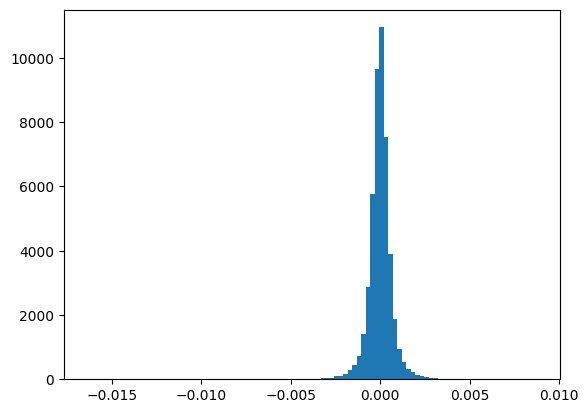

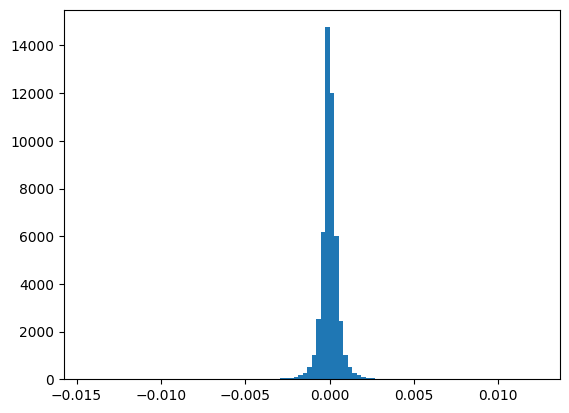

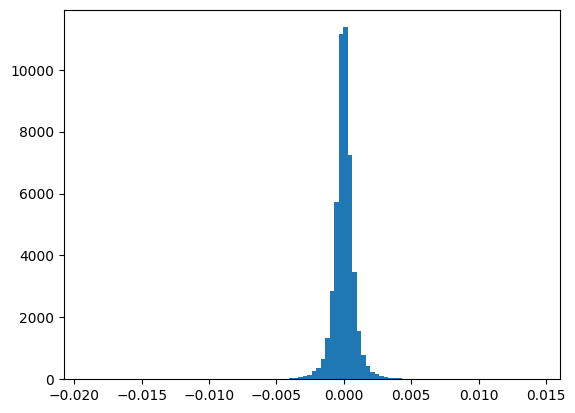

In [70]:
plt.hist(hrn_ret['ret'], bins=100)
plt.show()
plt.hist(kst_ret['ret'], bins=100)
plt.show()
plt.hist(plv_ret['ret'], bins=100)
plt.show()

In [ ]:
# volatility within the day
hrn_vol = hrn_ret.groupby('date')['ret'].std()
kst_vol = kst_ret.groupby('date')['ret'].std()
plv_vol = plv_ret.groupby('date')['ret'].std()
print(hrn_vol.describe(), kst_vol.describe(), plv_vol.describe())

count    125.000000
mean       0.000601
std        0.000328
min        0.000265
25%        0.000430
50%        0.000499
75%        0.000617
max        0.002260
Name: ret, dtype: float64 count    125.000000
mean       0.000483
std        0.000260
min        0.000204
25%        0.000349
50%        0.000403
75%        0.000488
max        0.001654
Name: ret, dtype: float64 count    125.000000
mean       0.000732
std        0.000400
min        0.000301
25%        0.000521
50%        0.000624
75%        0.000731
max        0.002485
Name: ret, dtype: float64


In [76]:
# volatility across days
hrn_vol_across = hrn_ret.groupby('date')['ret'].mean().std()
kst_vol_across = kst_ret.groupby('date')['ret'].mean().std()
plv_vol_across = plv_ret.groupby('date')['ret'].mean().std()
print(hrn_vol_across, kst_vol_across, plv_vol_across)

5.0937701769540066e-05 2.9963746394377905e-05 5.2458004096412837e-05


## A2

In [77]:
df

,ts,instrument,mid_close,spread_close,last_price,buy_volume,sell_volume,n_trades,minute,bid_px1,ask_px1,bid_sz1,ask_sz1,bid_sz2,ask_sz2,ret,date
0,2024-01-02 09:31:00,HRN,1998.300,0.20,1998.20,80,474,268,2024-01-02 09:30:00,1998.20,1998.40,40.0,36.0,136.0,45.0,NaN,2024-01-02
1,2024-01-02 09:31:00,KST,4997.625,0.25,4997.75,1269,978,585,2024-01-02 09:30:00,4997.50,4997.75,72.0,7.0,41.0,55.0,NaN,2024-01-02
2,2024-01-02 09:31:00,PLV,798.850,0.10,798.80,28,570,316,2024-01-02 09:30:00,798.80,798.90,38.0,1.0,30.0,26.0,NaN,2024-01-02
3,2024-01-02 09:32:00,HRN,1999.000,0.20,1998.90,191,319,241,2024-01-02 09:31:00,1998.90,1999.10,13.0,57.0,8.0,83.0,0.000350,2024-01-02
4,2024-01-02 09:32:00,KST,4997.625,0.25,4997.75,265,1161,334,2024-01-02 09:31:00,4997.50,4997.75,157.0,29.0,51.0,162.0,0.000000,2024-01-02
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
145683,2024-06-28 15:59:00,KST,4042.125,0.25,4042.25,5570,12,1476,2024-06-28 15:58:00,4042.00,4042.25,93.0,5.0,135.0,3.0,0.002045,2024-06-28
145684,2024-06-28 15:59:00,PLV,691.625,0.15,691.70,871,4,410,2024-06-28 15:58:00,691.55,691.70,25.0,9.0,37.0,1.0,0.002282,2024-06-28
145685,2024-06-28 16:00:00,HRN,1529.600,0.20,1529.70,329,168,256,2024-06-28 15:59:00,1529.50,1529.70,33.0,44.0,21.0,127.0,-0.000196,2024-06-28
145686,2024-06-28 16:00:00,KST,4042.125,0.25,4042.00,241,698,251,2024-06-28 15:59:00,4042.00,4042.25,165.0,3.0,232.0,4.0,0.000000,2024-06-28


In [78]:
df['ofi'] = (df['buy_volume'] - df['sell_volume']) / (df['buy_volume'] + df['sell_volume'])
df['obi'] = (df['bid_sz1'] - df['ask_sz1']) / (df['bid_sz1'] + df['ask_sz1'])
df['ret_m1'] = df.groupby(['date', 'instrument'])['ret'].shift(-1)
df['ret_m5'] = df.groupby(['date', 'instrument'])['ret'].shift(-5)
df['ret_m15'] = df.groupby(['date', 'instrument'])['ret'].shift(-15)
df['ret_m30'] = df.groupby(['date', 'instrument'])['ret'].shift(-30)

In [83]:
hrn_df = df.loc[df['instrument'] == 'HRN', ['ts', 'ofi', 'obi', 'ret', 'ret_m1', 'ret_m5', 'ret_m15', 'ret_m30']]
np.corrcoef(df.dropna()['ofi'], df.dropna()['ret_m5'])

array([[1.00000000e+00, 7.05180878e-04],
       [7.05180878e-04, 1.00000000e+00]])